# 13 · Measure, Don't Assume (Benchmark Lab)

**NHyDB 0.27.1 notebook series · v1**

A measuring lab you run on **your** machine. The same data goes through three phases – write, index, read – and every number in this notebook is measured here and now: medians of repeated runs with their spread, together with a description of the machine. No result is a promise for other hardware.

> **Who is this for?** This notebook starts with a short introduction and continues with runnable examples. **New to NHyDB?** Read from top to bottom – every idea is introduced before it is used. **Already know the basics?** Skip the sections marked 📘 *Background* and jump to the experiments marked ▶. All cells run from top to bottom; optional deep dives are marked ⏩ *Advanced*.

**What you will learn**

* how batch size, commit frequency and durability (`fsync` / `full`) affect writing
* what building secondary indexes costs, in time and in bytes
* reading by address vs. filtering by value – without and with an index
* how to read benchmark numbers honestly: medians, spread, conditions
* an optional orientation comparison with SQLite from the Python standard library

**Recommended before:** [10 · NumPy Batches](10_numpy_batches_v1.ipynb); [08](08_addresses_are_not_indexes_v1.ipynb) for indexes.

### Setup

The next cell checks the environment and defines a few small plotting helpers used in
this notebook. It is collapsed because it is not about NHyDB itself – feel free to open
it. Every database in this notebook lives in a temporary folder that is removed at
the end.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.27.1"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

import platform
import random
import sqlite3
import statistics
import time

import numpy as np
import pandas as pd
from nhydb.query import Q, QueryEngine


def measure(fn, repeats):
    """Run fn() `repeats` times; return (median, min, max) of the wall-clock seconds."""
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return statistics.median(times), min(times), max(times)


def errbars(df, value, scale=1.0):
    """Asymmetric error bars (min … max) for a column of rates derived from seconds."""
    return [(df[value] - df[value + "_lo"]) * scale, (df[value + "_hi"] - df[value]) * scale]

Python 3.14.5 · nhydb 0.27.1 · file format 0.16 · matplotlib 3.11.2


## 📘 Background: how to read a benchmark

* **One scenario, one machine.** A number describes exactly the scenario that produced it:
  data, batch size, commit pattern, durability, file system, cache state, hardware.
* **Median and spread.** Each measurement is repeated; we show the **median** and the range
  from the fastest to the slowest run (error bars). The first run is often slower (cold caches).
* **Compare like with like.** Reading a known address and searching for a value are different
  tasks; comparing their speed says nothing about "which is better".
* **Python vs. Rust.** Everything here runs through the Python API. The technical documentation
  reports separate numbers for the pure Rust core (see the box at the end); they are not
  comparable with the Python measurements below.

## 0 · ▶ Settings and machine

**Change it:** choose the data sizes. `large` (2 million records) is off by default – it takes
a few minutes and about 150 MB of temporary disk space.

In [2]:
# ▶ Try it: change these values and re-run the notebook
SCALES = {"small": 20_000, "medium": 200_000}
RUN_LARGE = False                       # adds "large": 2,000,000 records
REPEATS = 3                             # repetitions per measurement (median is reported)
RUN_SQLITE = True                       # optional orientation comparison with SQLite

if RUN_LARGE:
    SCALES["large"] = 2_000_000

machine = {
    "system": f"{platform.system()} {platform.release()} ({platform.machine()})",
    "processor": platform.processor() or "unknown",
    "cpu cores": os.cpu_count(),
    "python": platform.python_version(),
    "nhydb": nhydb.ENGINE_VERSION,
    "numpy": np.__version__,
    "sqlite": sqlite3.sqlite_version,
    "data folder": WORKDIR,
}
pd.Series(machine, name="measured on").to_frame()

,measured on
system,Darwin 25.6.0 (arm64)
processor,arm
cpu cores,8
python,3.14.5
nhydb,0.27.1
numpy,2.5.4
sqlite,3.50.4
data folder,/tmp/claude-501/nhydb_notebook_fe72ztvm


## 1 · The data

Synthetic measurements, deterministic (fixed random seed): an id, one of 50 stations, a value,
a flag and a short note. One CLASSIC layout, record = `u`.

In [3]:
STATION_NAMES = np.array([f"S{i:02d}" for i in range(50)], dtype=object)
WORDS = np.array(["calm", "windy", "rain", "dry", "storm", "fog", "clear", "cold", "warm", "snow"], dtype=object)


def make_columns(n, seed=42):
    rng = np.random.default_rng(seed)
    w1, w2 = rng.integers(0, len(WORDS), n), rng.integers(0, len(WORDS), n)
    return {
        "id": np.arange(1, n + 1, dtype=np.uint64),
        "station": STATION_NAMES[rng.integers(0, 50, n)],
        "value": rng.normal(20.0, 5.0, n),
        "flag": rng.random(n) < 0.1,
        "note": np.array([f"{a} and {b}" for a, b in zip(WORDS[w1], WORDS[w2])], dtype=object),
    }


SHAPE = [{"v": 1, "name": "id", "type": "varuint"}, {"v": 2, "name": "station", "type": "utf8"},
         {"v": 3, "name": "value", "type": "f64"}, {"v": 4, "name": "flag", "type": "bool"},
         {"v": 5, "name": "note", "type": "utf8"}]


def fresh_db(name, durability="fsync"):
    path = db_path(name)
    db = nhydb.create(path, overwrite=True, durability=durability)
    db.create_realm(1, "bench")
    db.create_shape(1, 1, "sample", SHAPE)
    db.create_classic_layout(1, 1, "samples", shape_id=1)
    db.commit()
    return db, path


def slice_cols(cols, a, b):
    return {k: v[a:b] for k, v in cols.items()}


DATA = {scale: make_columns(n) for scale, n in SCALES.items()}
pd.DataFrame(slice_cols(DATA["small"], 0, 5))

,id,station,value,flag,note
0,1,S45,10.509966,False,calm and calm
1,2,S37,15.770684,False,cold and cold
2,3,S10,15.028822,False,clear and rain
3,4,S49,16.648546,False,storm and cold
4,5,S49,21.499419,False,storm and fog


---
# Phase 1 · Writing

### 1a · Batch size

**Question:** How large should a batch be? All records are written with `put_numpy_batch` in
batches of the given size and committed once at the end.

In [4]:
BATCH_SIZES = [100, 1_000, 10_000, 100_000]
rows = []
for scale, n in SCALES.items():
    cols = DATA[scale]
    for bs in BATCH_SIZES:
        if bs > n:
            continue

        def run():
            db, _ = fresh_db("batch.nhydb")
            for a in range(0, n, bs):
                db.put_numpy_batch(1, a + 1, slice_cols(cols, a, min(a + bs, n)), shape_id=1)
            db.commit()
            db.close()

        med, lo, hi = measure(run, REPEATS)
        rows.append({"scale": scale, "records": n, "batch": bs, "rate": n / med, "rate_lo": n / hi, "rate_hi": n / lo})
write_batch = pd.DataFrame(rows)
write_batch.pivot(index="batch", columns="scale", values="rate").round(0)

scale,medium,small
batch,,
100,2865986.0,2568108.0
1000,4468059.0,3354790.0
10000,4548728.0,1704672.0
100000,4711347.0,NaN


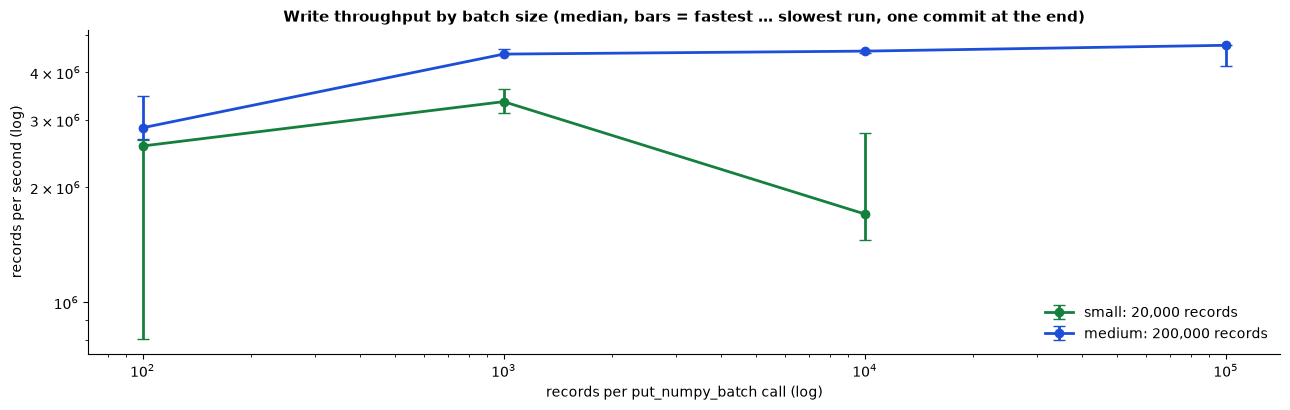

In [5]:
fig, ax = plt.subplots(figsize=(13, 4.2))
for scale, color in zip(SCALES, [COLORS["B"], COLORS["A"], COLORS["C"]]):
    part = write_batch[write_batch["scale"] == scale]
    ax.errorbar(part["batch"], part["rate"], yerr=errbars(part, "rate"), fmt="o-", color=color, lw=2,
                capsize=4, label=f"{scale}: {SCALES[scale]:,} records")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("records per put_numpy_batch call (log)")
ax.set_ylabel("records per second (log)")
ax.set_title("Write throughput by batch size (median, bars = fastest … slowest run, one commit at the end)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**What happened?** Small batches pay the per-call cost often; from a few thousand records per
call the curve flattens – the engine is then limited by encoding and writing, not by Python.

### 1b · Commit frequency and durability

**Question:** What does a commit cost? A commit writes the pending data, **syncs the file to
disk** and moves the commit boundary. `durability="full"` additionally asks the drive to flush
its own cache (on macOS `F_FULLFSYNC`; on Linux and Windows both modes perform the same call).

In [6]:
n = SCALES["small"]
cols = DATA["small"]
BATCH = 1_000
COMMIT_EVERY = [20, 5, 1]                     # commit after every k batches → n/(k·BATCH) commits

rows = []
for durability in ("fsync", "full"):
    for k in COMMIT_EVERY:
        def run():
            db, _ = fresh_db("commit.nhydb", durability=durability)
            for i, a in enumerate(range(0, n, BATCH)):
                db.put_numpy_batch(1, a + 1, slice_cols(cols, a, a + BATCH), shape_id=1)
                if (i + 1) % k == 0:
                    db.commit()
            db.commit()
            db.close()
        try:
            med, lo, hi = measure(run, REPEATS)
        except nhydb.NHyDBError as e:                  # e.g. file system without F_FULLFSYNC
            print(f"durability={durability}: not available here ({e})")
            continue
        commits = n // (k * BATCH)
        rows.append({"durability": durability, "commits": commits, "total ms": 1000 * med, "rate": n / med,
                     "rate_lo": n / hi, "rate_hi": n / lo})
commit_df = pd.DataFrame(rows)
commit_df[["durability", "commits", "total ms", "rate"]].round(1)

,durability,commits,total ms,rate
0,fsync,1,5.2,3820439.4
1,fsync,4,5.1,3906377.4
2,fsync,20,7.3,2741071.4
3,full,1,50.0,400378.7
4,full,4,71.4,280015.0
5,full,20,185.0,108098.2


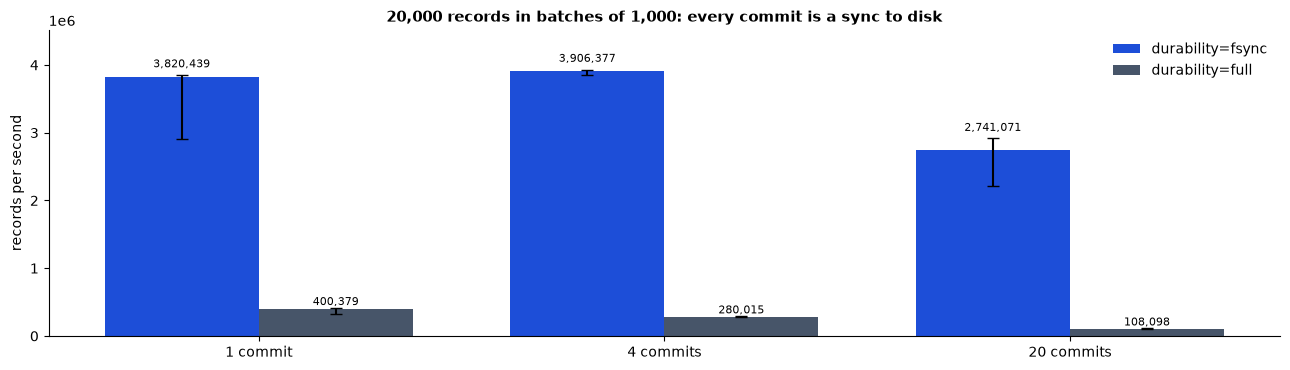

In [7]:
fig, ax = plt.subplots(figsize=(13, 3.8))
width = 0.38
for j, (durability, color) in enumerate((("fsync", COLORS["A"]), ("full", COLORS["C"]))):
    part = commit_df[commit_df["durability"] == durability]
    if part.empty:
        continue
    x = np.arange(len(part)) + (j - 0.5) * width
    ax.bar(x, part["rate"], width, yerr=errbars(part, "rate"), capsize=4, color=color, label=f"durability={durability}")
    for xi, top, r in zip(x, part["rate_hi"], part["rate"]):
        ax.text(xi, top * 1.02, f"{r:,.0f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(range(len(COMMIT_EVERY)))
ax.set_xticklabels([f"{n // (k * BATCH)} commit{'s' if n // (k * BATCH) > 1 else ''}" for k in COMMIT_EVERY])
ax.set_ylim(0, commit_df["rate_hi"].max() * 1.15)
ax.set_ylabel("records per second")
ax.set_title(f"{n:,} records in batches of {BATCH:,}: every commit is a sync to disk")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**What happened?** The more often you commit, the more often the data is synced to disk – and
syncs are the slowest part of writing. `full` asks even more of the drive. The trade-off is
**durability vs. speed**: everything after the last commit is discarded after a crash
(notebook 11). Commit when a unit of work is complete, not after every record.

---
# Phase 2 · Indexing

**Question:** What does building secondary indexes cost? We write the data once (one commit),
then build each index separately and measure time and file growth.

In [8]:
INDEXES = [
    ("VALUE on station (50 distinct)", lambda db: db.create_index(1, 1, "by_station", "station")),
    ("VALUE on value (all distinct)",  lambda db: db.create_index(2, 1, "by_value", "value")),
    ("TOKEN on note",                  lambda db: db.create_token_index(3, 1, "tok_note", "note")),
    ("FULLTEXT on note",               lambda db: db.create_fulltext_index(4, 1, "ft_note", "note")),
]
INDEX_PATHS = {}
rows = []
for scale, n in SCALES.items():
    db, path = fresh_db(f"indexed_{scale}.nhydb")
    db.put_numpy_batch(1, 1, DATA[scale], shape_id=1, commit=True)
    base = os.path.getsize(path)
    for index_id, (label, create) in enumerate(INDEXES, start=1):
        create(db)
        t0 = time.perf_counter()
        db.build_indexes([index_id], commit=True)
        seconds = time.perf_counter() - t0
        size = os.path.getsize(path)
        rows.append({"scale": scale, "index": label, "build s": seconds, "MB added": (size - base) / 1e6,
                     "bytes per record": (size - base) / n})
        base = size
    db.close()
    INDEX_PATHS[scale] = path
index_df = pd.DataFrame(rows)
index_df.round(3)

,scale,index,build s,MB added,bytes per record
0,small,VALUE on station (50 distinct),0.005,0.039,1.950
1,small,VALUE on value (all distinct),0.074,0.731,36.572
2,small,TOKEN on note,0.010,0.082,4.118
3,small,FULLTEXT on note,0.013,0.044,2.206
4,medium,VALUE on station (50 distinct),0.037,0.344,1.719
5,medium,VALUE on value (all distinct),0.765,7.349,36.744
6,medium,TOKEN on note,0.091,0.814,4.069
7,medium,FULLTEXT on note,0.127,0.429,2.143


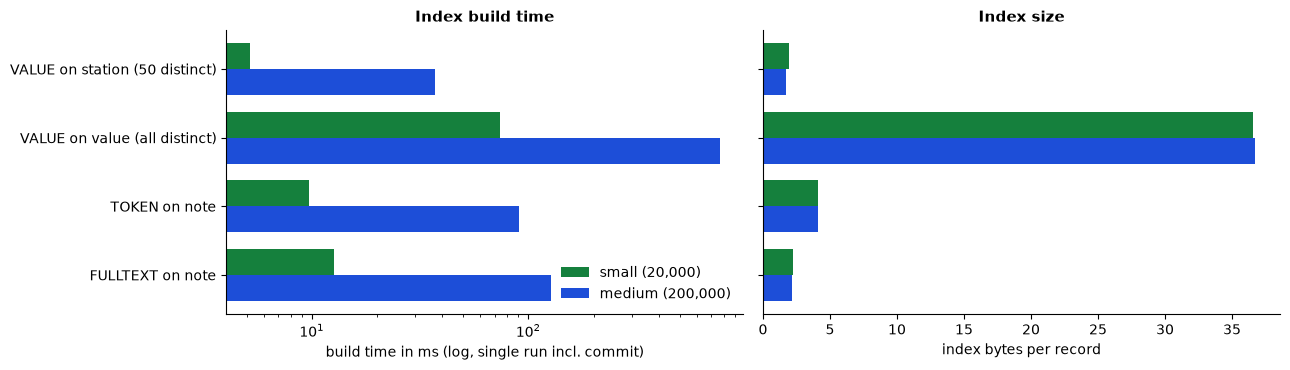

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
labels = [x[0] for x in INDEXES]
for j, (scale, color) in enumerate(zip(SCALES, [COLORS["B"], COLORS["A"]])):
    part = index_df[index_df["scale"] == scale].set_index("index").loc[labels]
    y = np.arange(len(labels)) + (j - 0.5) * 0.38
    ax1.barh(y, part["build s"] * 1000, 0.38, color=color, label=f"{scale} ({SCALES[scale]:,})")
    ax2.barh(y, part["bytes per record"], 0.38, color=color)
for ax in (ax1, ax2):
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    ax.invert_yaxis()
ax2.set_yticklabels([])
ax1.set_xscale("log")
ax1.set_xlabel("build time in ms (log, single run incl. commit)")
ax2.set_xlabel("index bytes per record")
ax1.set_title("Index build time")
ax2.set_title("Index size")
ax1.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

**What happened?** Indexes are real data structures: they take time to build and space in the
file. Text indexes (TOKEN, FULLTEXT) store word positions and cost more than a VALUE index on a
column with few distinct values. Indexes are built **explicitly** with `build_indexes()` –
the write phase above was not slowed down by them.

---
# Phase 3 · Reading

**Question:** How fast can we get data back – by address, and by value?

| Task | Method | Index used? |
|---|---|---|
| a block of records by address | `read_numpy(realm, u_start, count)` | no index needed |
| 2,000 single records at random addresses | `get_record` | no index needed |
| count records with `station == "S07"` | QueryEngine count | scan **or** VALUE index |
| count records with `19.9 ≤ value ≤ 20.1` | QueryEngine count | scan **or** VALUE index |

The "without index" numbers come from a copy of the data without indexes; the database files
were just written, so they are in the operating system's cache (**warm** reads).

In [10]:
POINTS = 2_000
rows = []
for scale, n in SCALES.items():
    plain_db, _ = fresh_db(f"plain_{scale}.nhydb")
    plain_db.put_numpy_batch(1, 1, DATA[scale], shape_id=1, commit=True)
    indexed_db = nhydb.open(INDEX_PATHS[scale])
    us = random.Random(1).sample(range(1, n + 1), POINTS)
    station_q = Q.field("station") == "S07"
    value_q = Q.field("value").between(19.9, 20.1)
    expected_station = int((DATA[scale]["station"] == "S07").sum())

    tasks = [
        ("read_numpy block (by address)", n, lambda: indexed_db.read_numpy(1, 1, n, ["value"])),
        ("random get_record (by address)", POINTS, lambda: [indexed_db.get_record(1, u) for u in us]),
        ("station == S07 · scan", n, lambda: QueryEngine(plain_db).execute(station_q, realm=1, return_mode="count")),
        ("station == S07 · index", n, lambda: QueryEngine(indexed_db).execute(station_q, realm=1, return_mode="count")),
        ("value range · scan", n, lambda: QueryEngine(plain_db).execute(value_q, realm=1, return_mode="count")),
        ("value range · index", n, lambda: QueryEngine(indexed_db).execute(value_q, realm=1, return_mode="count")),
    ]
    for label, units, fn in tasks:
        med, lo, hi = measure(fn, REPEATS)
        rows.append({"scale": scale, "task": label, "median ms": med * 1000, "lo ms": lo * 1000, "hi ms": hi * 1000,
                     "records/s": units / med})
    # the scan and the index give the same answers
    assert QueryEngine(plain_db).execute(station_q, realm=1, return_mode="count")["count"] == expected_station
    assert QueryEngine(indexed_db).execute(station_q, realm=1, return_mode="count")["count"] == expected_station
    assert QueryEngine(indexed_db).explain(station_q, realm=1)["plan"]["access"] == "VALUE_INDEX"
    assert QueryEngine(plain_db).explain(station_q, realm=1)["plan"]["access"] == "MATERIALIZED_SCAN"
    plain_db.close()
    indexed_db.close()
read_df = pd.DataFrame(rows)
read_df.pivot(index="task", columns="scale", values="median ms").round(2)

scale,medium,small
task,,
random get_record (by address),3.10,3.11
read_numpy block (by address),6.43,0.64
station == S07 · index,0.01,0.01
station == S07 · scan,210.06,19.61
value range · index,0.25,0.03
value range · scan,202.45,19.70


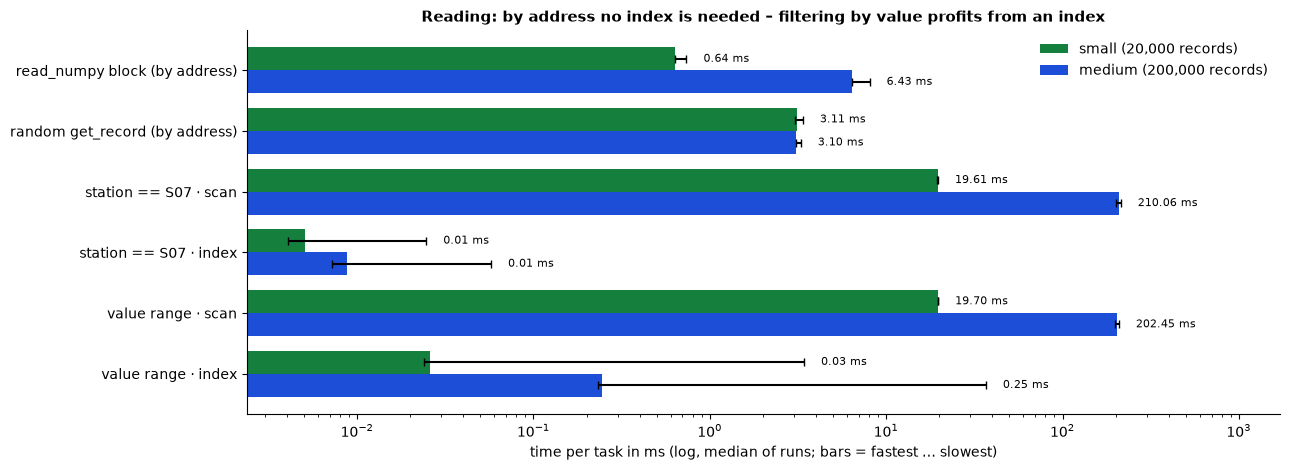

In [11]:
fig, ax = plt.subplots(figsize=(13, 4.8))
tasks = list(dict.fromkeys(read_df["task"]))
for j, (scale, color) in enumerate(zip(SCALES, [COLORS["B"], COLORS["A"]])):
    part = read_df[read_df["scale"] == scale].set_index("task").loc[tasks]
    y = np.arange(len(tasks)) + (j - 0.5) * 0.38
    ax.barh(y, part["median ms"], 0.38, xerr=[part["median ms"] - part["lo ms"], part["hi ms"] - part["median ms"]],
            capsize=3, color=color, label=f"{scale} ({SCALES[scale]:,} records)")
    for yi, ms, hi in zip(y, part["median ms"], part["hi ms"]):
        ax.text(hi * 1.25, yi, f"{ms:.2f} ms", va="center", fontsize=8)
ax.set_yticks(range(len(tasks)))
ax.set_yticklabels(tasks)
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("time per task in ms (log, median of runs; bars = fastest … slowest)")
ax.set_title("Reading: by address no index is needed – filtering by value profits from an index")
ax.set_xlim(right=read_df["hi ms"].max() * 8)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

**What happened?**

* **By address** nothing is searched: a block of records comes back as NumPy columns, and
  random single records are found by computing their cells.
* **By value** the engine must either look at every record (**scan**) or ask an index. The
  index pays off most when the answer is a small part of the data. A **count** over a VALUE
  index can even be answered from the index entries alone, without reading a single record –
  that is why `station == "S07" · index` takes only microseconds. Single runs of very short
  tasks vary a lot (wide error bars); the median is the robust number.
* The two kinds of task answer different questions – their times are shown side by side, not
  as a competition.

---
# Phase 4 · Optional: an orientation comparison with SQLite

SQLite is part of the Python standard library, so it is a convenient reference. This is an
**orientation measurement**, not a verdict: SQLite is a mature relational engine with a
different design, and both engines could be tuned further. The settings used:

* SQLite: file database, `PRAGMA journal_mode=DELETE`, `PRAGMA synchronous=FULL` (durable
  commits), all inserts in **one transaction** with `executemany`, `id INTEGER PRIMARY KEY`.
* NHyDB: `durability="fsync"`, `put_numpy_batch` in batches of 10,000, **one commit**.
* Both get their input prepared before the clock starts (SQLite: a list of tuples, NHyDB: NumPy
  columns), so neither pays for building it.

In [12]:
def sqlite_run(n, cols):
    path = db_path(f"compare_{n}.sqlite")
    if os.path.exists(path):
        os.remove(path)
    con = sqlite3.connect(path)
    con.execute("PRAGMA journal_mode=DELETE")
    con.execute("PRAGMA synchronous=FULL")
    con.execute("CREATE TABLE samples (id INTEGER PRIMARY KEY, station TEXT, value REAL, flag INTEGER, note TEXT)")
    data = list(zip(cols["id"].tolist(), cols["station"].tolist(), cols["value"].tolist(),
                    cols["flag"].tolist(), cols["note"].tolist()))
    out = {}
    t0 = time.perf_counter()
    with con:
        con.executemany("INSERT INTO samples VALUES (?, ?, ?, ?, ?)", data)
    out["write"] = time.perf_counter() - t0
    t0 = time.perf_counter()
    con.execute("CREATE INDEX by_station ON samples(station)")
    con.commit()
    out["index"] = time.perf_counter() - t0
    us = random.Random(1).sample(range(1, n + 1), POINTS)
    out["points"], _, _ = measure(lambda: [con.execute("SELECT * FROM samples WHERE id = ?", (u,)).fetchone() for u in us], REPEATS)
    out["filter"], _, _ = measure(lambda: con.execute("SELECT COUNT(*) FROM samples WHERE station = 'S07'").fetchone(), REPEATS)
    pragmas = (con.execute("PRAGMA journal_mode").fetchone()[0], con.execute("PRAGMA synchronous").fetchone()[0])
    con.close()
    out["file MB"] = os.path.getsize(path) / 1e6
    return out, pragmas, data


def nhydb_run(n, cols):
    db, path = fresh_db(f"compare_{n}.nhydb")
    out = {}
    t0 = time.perf_counter()
    for a in range(0, n, 10_000):
        db.put_numpy_batch(1, a + 1, slice_cols(cols, a, min(a + 10_000, n)), shape_id=1)
    db.commit()
    out["write"] = time.perf_counter() - t0
    db.create_index(1, 1, "by_station", "station")
    t0 = time.perf_counter()
    db.build_indexes(commit=True)
    out["index"] = time.perf_counter() - t0
    us = random.Random(1).sample(range(1, n + 1), POINTS)
    out["points"], _, _ = measure(lambda: [db.get_record(1, u) for u in us], REPEATS)
    q = QueryEngine(db)
    out["filter"], _, _ = measure(lambda: q.execute(Q.field("station") == "S07", realm=1, return_mode="count"), REPEATS)
    db.close()
    out["file MB"] = os.path.getsize(path) / 1e6
    return out


if RUN_SQLITE:
    rows = []
    for scale, n in SCALES.items():
        lite, pragmas, _ = sqlite_run(n, DATA[scale])
        nh = nhydb_run(n, DATA[scale])
        for engine, res in (("NHyDB", nh), ("SQLite", lite)):
            rows.append({"scale": scale, "engine": engine,
                         "write (records/s)": n / res["write"], "index build (ms)": res["index"] * 1000,
                         f"{POINTS:,} point reads (ms)": res["points"] * 1000,
                         "count station=S07 (ms)": res["filter"] * 1000, "file MB": res["file MB"]})
    compare = pd.DataFrame(rows)
    print(f"SQLite pragmas in effect: journal_mode={pragmas[0]}, synchronous={pragmas[1]} (2 = FULL)")
    display(compare.set_index(["scale", "engine"]).round(2))

SQLite pragmas in effect: journal_mode=delete, synchronous=2 (2 = FULL)


write (records/s)  index build (ms)  2,000 point reads (ms)  \
scale  engine                                                                
small  NHyDB          5194411.23              4.93                    3.08   
       SQLite         1570747.41              4.50                   10.18   
medium NHyDB          5248414.00             35.60                    3.15   
       SQLite         1488913.18             54.54                   11.83   

               count station=S07 (ms)  file MB  
scale  engine                                   
small  NHyDB                     0.01     0.72  
       SQLite                    0.01     0.95  
medium NHyDB                     0.01     7.18  
       SQLite                    0.08     9.68

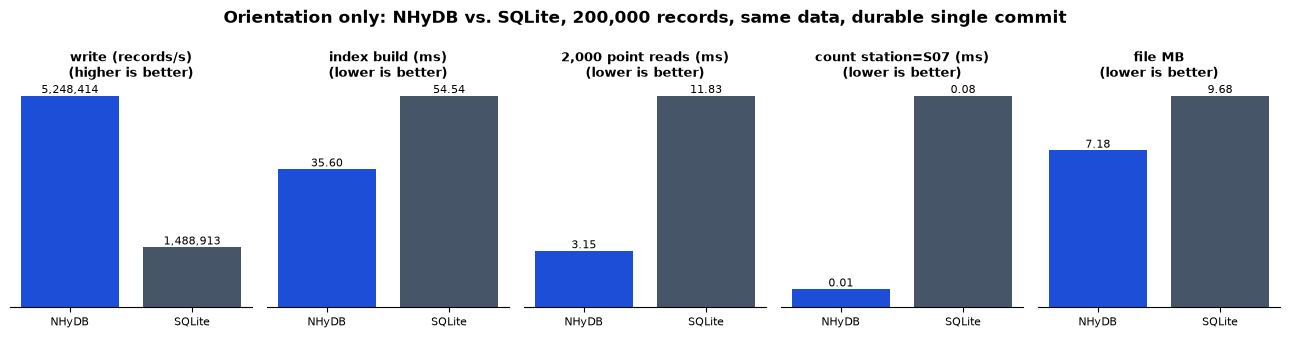

In [13]:
if RUN_SQLITE:
    metrics = ["write (records/s)", "index build (ms)", f"{POINTS:,} point reads (ms)", "count station=S07 (ms)", "file MB"]
    better = ["higher", "lower", "lower", "lower", "lower"]
    biggest = list(SCALES)[-1]
    part = compare[compare["scale"] == biggest].set_index("engine")
    fig, axes = plt.subplots(1, len(metrics), figsize=(13, 3.4))
    for ax, metric, b in zip(axes, metrics, better):
        vals = part[metric]
        ax.bar(vals.index, vals.values, color=[COLORS["A"], COLORS["C"]])
        for i, v in enumerate(vals.values):
            ax.text(i, v, f"{v:,.0f}" if v > 100 else f"{v:.2f}", ha="center", va="bottom", fontsize=8)
        ax.set_title(f"{metric}\n({b} is better)", fontsize=9)
        ax.tick_params(axis="x", labelsize=8)
        ax.set_yticks([])
        ax.spines["left"].set_visible(False)
    fig.suptitle(f"Orientation only: NHyDB vs. SQLite, {SCALES[biggest]:,} records, same data, durable single commit",
                 fontweight="bold")
    plt.tight_layout()
    plt.show()

**How to read this comparison:** it shows how the two engines behave **for this data, these
settings and this machine** through their Python interfaces. It does not cover concurrency,
complex SQL, joins (SQLite) or mathematical addressing, MATH layouts and Dynadron queries
(NHyDB). Change the settings, and the picture may change.

---
## 📘 Context: the documented numbers of the Rust core

The technical documentation (section 18.5) reports measurements of the **pure Rust core**
(no Python), on a MacBook Air M2, macOS 26.6.2, release build, one run each, 1 million
synthetic records with 11 integer fields, batch 10,000, commit every 10 batches:

| Scenario | `fsync` | `full` |
|---|---:|---:|
| BASE_ONLY | 14.2 million records/s | 6.9 million records/s |
| RESERVE_ONLY | 18.8 million records/s | 7.7 million records/s |
| SPARSE_MIX (plus 710,000 sparse cells) | 5.7 million records/s | 4.1 million records/s |

These figures come from a different program (`cargo run --release -p nhydb-core --example
bench_native`), different data and no Python layer. They are quoted for context only and are
**not** comparable with the measurements in this notebook.

## Your turn

**Task:** does writing get faster if the 10 % flagged records are left out? Measure
`put_numpy_batch` for the full small data set and for the unflagged records only (as one
consecutive block) and compare records per second.

In [14]:
cols = DATA["small"]
keep = ~cols["flag"]
subset = {k: v[keep] for k, v in cols.items()}


def write_all(c):
    db, _ = fresh_db("task.nhydb")
    db.put_numpy_batch(1, 1, c, shape_id=1)
    db.commit()
    db.close()


full_med, _, _ = measure(lambda: write_all(cols), REPEATS)
sub_med, _, _ = measure(lambda: write_all(subset), REPEATS)
print(f"all {len(cols['id']):,} records: {len(cols['id']) / full_med:,.0f} records/s")
print(f"{int(keep.sum()):,} unflagged : {int(keep.sum()) / sub_med:,.0f} records/s")
print("→ the rate per record stays in the same range: fewer records mainly means less total time.")
assert keep.sum() < len(cols["id"])

all 20,000 records: 4,031,378 records/s
18,019 unflagged : 4,115,924 records/s
→ the rate per record stays in the same range: fewer records mainly means less total time.


## ⏩ Advanced: cold or warm?

All reads above are **warm**: the files were just written and sit in the operating system's
page cache. Truly cold reads (after a reboot or with the cache dropped) depend mostly on the
storage device and cannot be produced reliably from a notebook. If you need them, run the
read phase in a fresh process after clearing the cache with your operating system's tools, and
report the conditions together with the numbers.

## Summary

* Batches of a few thousand records or more remove most of the per-call overhead.
* Every commit is a sync to disk; `full` durability asks more of the drive – commit per unit of work.
* Indexes cost build time and space, are built explicitly and pay off for selective value filters.
* Reading by address needs no index; filtering by value scans or uses an index – different tasks, both measured.
* Every number here is a median with spread for this machine; the Rust core figures are separate context.

## Where to go next

* [10 · NumPy Batches](10_numpy_batches_v1.ipynb) – the write and read paths in detail.
* [11 · What Actually Lives on Disk?](11_what_lives_on_disk_v1.ipynb) – commits, crash safety and file layout.
* [14 · A Small Real Application](14_complete_application_v1.ipynb) – everything together.

**Cookbook sections:** 5 (Commit and durability), 13 (Secondary indexes), 16 (NumPy batch API) in the [NHyDB Python Cookbook](https://github.com/nhydb/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [15]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
